In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Upload the Mall Customers CSV file

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:
# Load the dataset

df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")

print("\nDataset shape:")
print(df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Dataset loaded successfully!

Dataset shape:
(200, 5)

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
# Select Annual Income and Spending Score

X = df[[
    "Annual Income (k$)",
    "Spending Score (1-100)"
]]

print("Selected features:")
display(X.head())

print("\nNumber of customers:", X.shape[0])
print("Number of features:", X.shape[1])

Selected features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Number of customers: 200
Number of features: 2


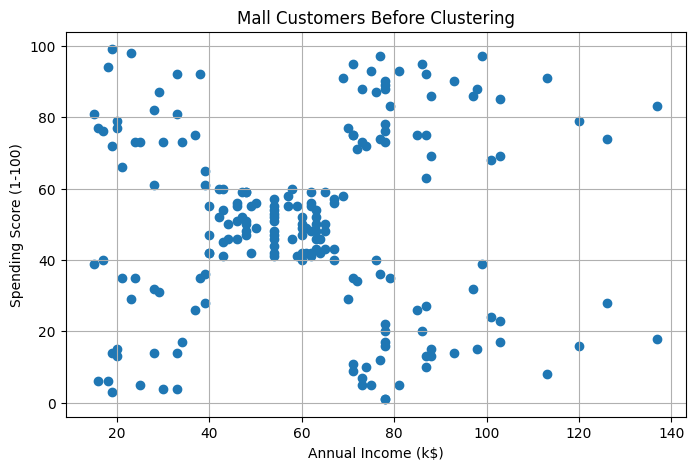

In [6]:
# Plot customers before clustering

plt.figure(figsize=(8, 5))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"]
)

plt.title("Mall Customers Before Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True)
plt.show()

In [7]:
# Standardize the selected features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed successfully!")

print("\nFirst five standardized records:")
print(X_scaled[:5])

Feature scaling completed successfully!

First five standardized records:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


WCSS values:
K = 1 WCSS = 400.0
K = 2 WCSS = 269.691
K = 3 WCSS = 157.704
K = 4 WCSS = 108.9213
K = 5 WCSS = 65.5684
K = 6 WCSS = 55.0573
K = 7 WCSS = 44.8648
K = 8 WCSS = 37.2282
K = 9 WCSS = 32.3923
K = 10 WCSS = 29.9819


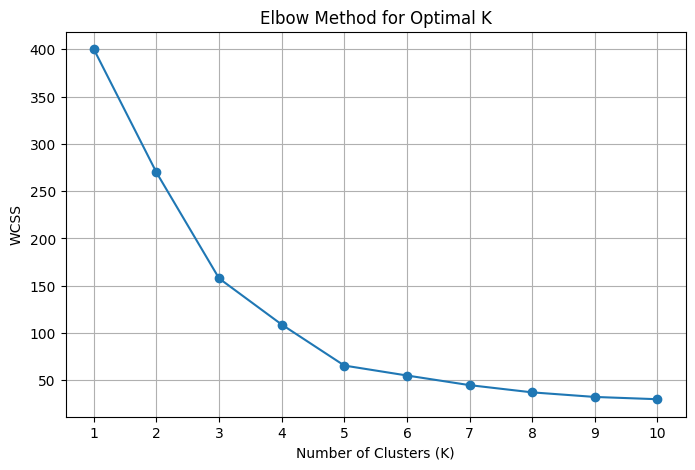

In [8]:
# Calculate WCSS for different values of K

wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

print("WCSS values:")
for k, value in enumerate(wcss, start=1):
    print("K =", k, "WCSS =", round(value, 4))

# Plot the Elbow graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [9]:
# Evaluate clustering quality for K = 2 to 10

evaluation_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)

    db_index = davies_bouldin_score(X_scaled, labels)

    evaluation_results.append({
        "K": k,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "WCSS": model.inertia_
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Clustering Evaluation Results:")

display(
    evaluation_df.style.format({
        "Silhouette Score": "{:.4f}",
        "Davies-Bouldin Index": "{:.4f}",
        "WCSS": "{:.4f}"
    })
)

# Identify the best K according to each metric

best_silhouette = evaluation_df.loc[
    evaluation_df["Silhouette Score"].idxmax()
]

best_db = evaluation_df.loc[
    evaluation_df["Davies-Bouldin Index"].idxmin()
]

print("\nBest K according to Silhouette Score:")
print(
    int(best_silhouette["K"]),
    "with score",
    round(best_silhouette["Silhouette Score"], 4)
)

print("\nBest K according to Davies-Bouldin Index:")
print(
    int(best_db["K"]),
    "with index",
    round(best_db["Davies-Bouldin Index"], 4)
)

Clustering Evaluation Results:


,K,Silhouette Score,Davies-Bouldin Index,WCSS
0,2,0.3213,1.2670,269.6910
1,3,0.4666,0.7165,157.7040
2,4,0.4939,0.7096,108.9213
3,5,0.5547,0.5722,65.5684
4,6,0.5399,0.6546,55.0573
5,7,0.5281,0.7148,44.8648
6,8,0.4552,0.7602,37.2282
7,9,0.4571,0.7632,32.3923
8,10,0.4432,0.7935,29.9819



Best K according to Silhouette Score:
5 with score 0.5547

Best K according to Davies-Bouldin Index:
5 with index 0.5722


In [10]:
# Set the selected number of clusters

optimal_k = 5

# Create and train the K-Means model

kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Assign a cluster to each customer

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")

print("\nFirst ten customer records with cluster labels:")
display(df.head(10))

print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

K-Means model trained successfully!

First ten customer records with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2



Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


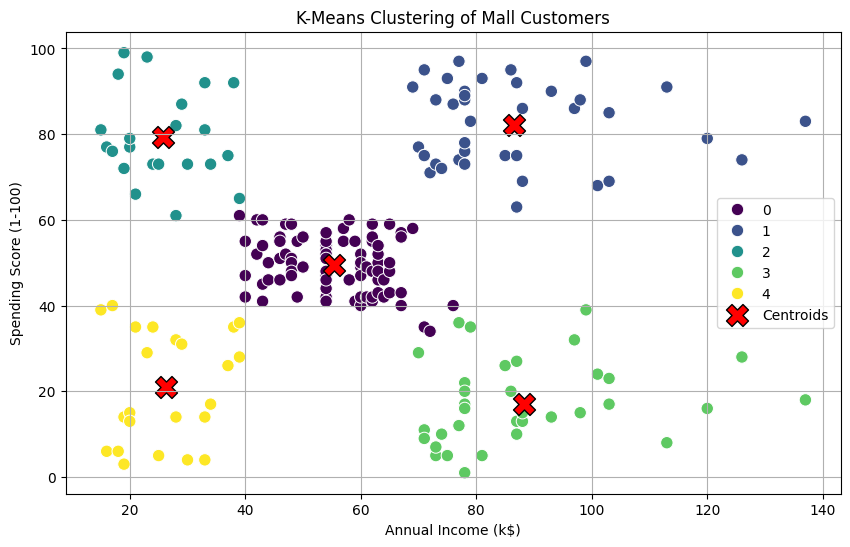

In [11]:
# Obtain centroids in the original feature scale

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# Plot the customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=80
)

# Plot the centroids

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.title("K-Means Clustering of Mall Customers")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Evaluate the final clustering model

final_labels = df["Cluster"]

final_silhouette = silhouette_score(
    X_scaled,
    final_labels
)

final_db_index = davies_bouldin_score(
    X_scaled,
    final_labels
)

print("Final K-Means Evaluation")
print("------------------------")

print("Number of clusters:", optimal_k)

print("Silhouette Score:",
      round(final_silhouette, 4))

print("Davies-Bouldin Index:",
      round(final_db_index, 4))

print("WCSS:",
      round(kmeans.inertia_, 4))

Final K-Means Evaluation
------------------------
Number of clusters: 5
Silhouette Score: 0.5547
Davies-Bouldin Index: 0.5722
WCSS: 65.5684


In [13]:
# Calculate average values for each customer cluster

cluster_summary = df.groupby("Cluster").agg({
    "Annual Income (k$)": ["mean", "min", "max"],
    "Spending Score (1-100)": ["mean", "min", "max"],
    "CustomerID": "count"
})

cluster_summary = cluster_summary.rename(
    columns={"CustomerID": "Customer Count"}
)

print("Customer Cluster Summary:")

display(cluster_summary.round(2))

Customer Cluster Summary:


Annual Income (k$)          Spending Score (1-100)          \
                      mean min  max                   mean min max   
Cluster                                                              
0                    55.30  39   76                  49.52  34  61   
1                    86.54  69  137                  82.13  63  97   
2                    25.73  15   39                  79.36  61  99   
3                    88.20  70  137                  17.11   1  39   
4                    26.30  15   39                  20.91   3  40   

        Customer Count  
                 count  
Cluster                 
0                   81  
1                   39  
2                   22  
3                   35  
4                   23

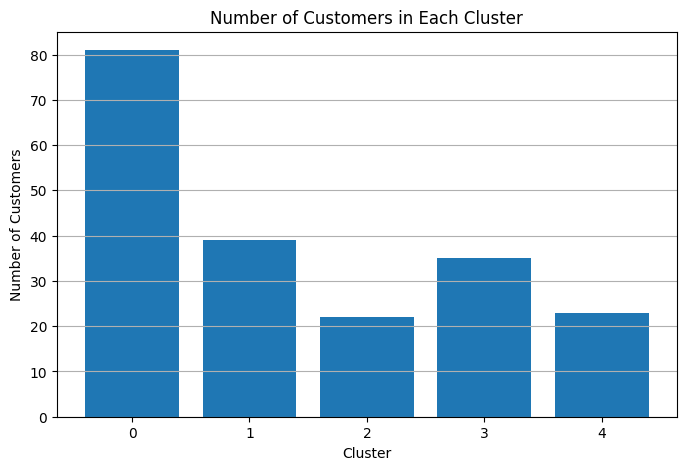

Customer count in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [14]:
# Count customers in each cluster

cluster_counts = df["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.grid(axis="y")
plt.show()

print("Customer count in each cluster:")
print(cluster_counts)

In [18]:

# Predict the cluster for new customers

# Enter new customer data
new_customers = pd.DataFrame({
    "Annual Income (k$)": [25, 80, 90],
    "Spending Score (1-100)": [75, 20, 85]
})

print("New Customer Data:")
display(new_customers)

# Scale the new data using the same scaler
new_customers_scaled = scaler.transform(new_customers)

# Predict the clusters
predicted_clusters = kmeans.predict(new_customers_scaled)

# Display predictions
new_customers["Predicted Cluster"] = predicted_clusters

print("\nPrediction Results:")
display(new_customers)

New Customer Data:


,Annual Income (k$),Spending Score (1-100)
0,25,75
1,80,20
2,90,85



Prediction Results:


,Annual Income (k$),Spending Score (1-100),Predicted Cluster
0,25,75,2
1,80,20,3
2,90,85,1
